In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Check missing values
print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False))

# Convert date columns to datetime
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Check numeric columns
numeric_cols = ["Sales", "Profit", "Quantity", "Discount"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nData after cleaning:", df.shape)
display(df.head())

Duplicate rows: 0

Missing values by column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Data after cleaning: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [1]:
from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = next(iter(uploaded))

df = pd.read_csv(file_name, encoding="latin1")

# Preview the data
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Dataset shape: (9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-nu

In [9]:
# Check data quality before cleaning
print("Rows before cleaning:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Clean column names
df.columns = df.columns.str.strip()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert dates to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

# Confirm the changes
print("Rows after cleaning:", len(df))
print("Date data types:")
print(df[["Order Date", "Ship Date"]].dtypes)

Rows before cleaning: 9994
Duplicate rows: 0
Missing values:
Series([], dtype: int64)
Rows after cleaning: 9994
Date data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [10]:
discount_analysis = (
    df.groupby("Discount")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Rows=("Discount", "size")
      )
      .sort_index()
      .round(2)
)

display(discount_analysis)

,Sales,Profit,Rows
Discount,,,
0.00,1087908.47,320987.60,4798
0.10,54369.35,9029.18,94
0.15,27558.52,1418.99,52
0.20,764594.37,90337.31,3657
0.30,103226.66,-10369.28,227
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,206
0.45,5484.97,-2493.11,11
0.50,58918.54,-20506.43,66


In [4]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Distinct Orders",
        "Unique Customers",
        "Profit Margin (%)"
    ],
    "Value": [
        round(total_sales, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        round(profit_margin, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Distinct Orders,5009.00
3,Unique Customers,793.00
4,Profit Margin (%),12.47


In [5]:
category_sales = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
      .round(2)
)

display(category_sales)

,Sales,Profit,Quantity
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


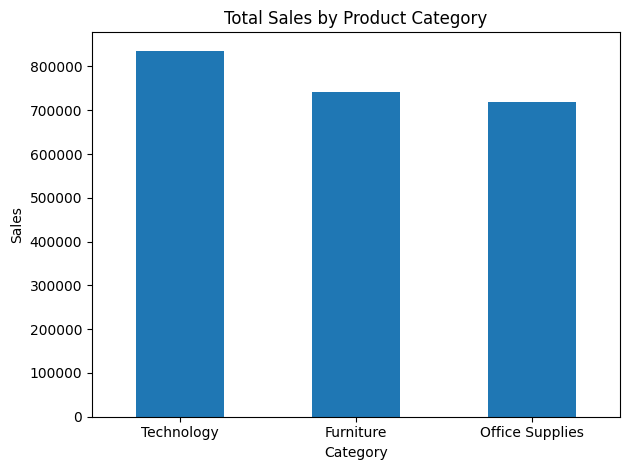

In [6]:
category_sales["Sales"].plot(
    kind="bar",
    title="Total Sales by Product Category",
    xlabel="Category",
    ylabel="Sales",
    rot=0
)

plt.tight_layout()
plt.show()

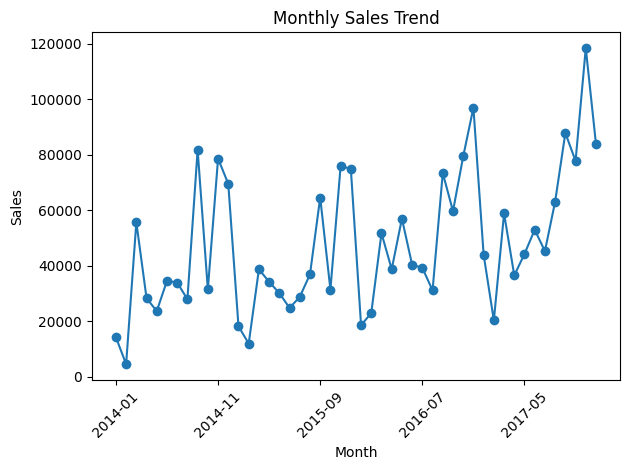

In [7]:
df["Order Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Order Month")["Sales"]
      .sum()
      .sort_index()
)

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend",
    xlabel="Month",
    ylabel="Sales"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
region_performance = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .sort_values("Profit", ascending=False)
      .round(2)
)

display(region_performance)

print("Highest-sales category:",
      category_sales["Sales"].idxmax())

print("Most-profitable category:",
      category_sales["Profit"].idxmax())

print("Most-profitable region:",
      region_performance["Profit"].idxmax())

,Sales,Profit
Region,,
West,725457.82,108418.45
East,678781.24,91522.78
South,391721.90,46749.43
Central,501239.89,39706.36


Highest-sales category: Technology
Most-profitable category: Technology
Most-profitable region: West
